# 作业 · 用 KNN 给鸢尾花分类

《数据分析与机器学习》

- 姓名：
- 学号：

## 1. 任务介绍

假设你在温室记录了一朵鸢尾花的四项测量结果：萼片长 6.3 cm、萼片宽 2.5 cm、花瓣长 4.9 cm、花瓣宽 1.5 cm。记录表里的「物种」一栏还没填。你需要根据这四个数值，判断它属于山鸢尾、变色鸢尾还是维吉尼亚鸢尾。

你手里有 150 朵来自这三个物种的鸢尾花记录，每朵都测量了同样的四项尺寸，也都有已知的物种标签。我们把这些记录分成两组。一组供模型查找邻居，另一组模拟一批待识别的花。对每朵待识别的花，KNN 根据四项尺寸寻找最相近的 5 个训练样本，让每个邻居投一票，并预测得票最多的物种。随后对照真实标签，检验预测是否正确。

完成后提交这一份 Notebook，保留运行输出和文字答案。按顺序运行单元，遇到标有 **TODO** 的代码，先补全带省略号 `...` 的位置。需要完成三项任务：

1. 用 `scikit-learn` 建立 KNN 分类器并预测测试样本的物种。
2. 根据 5 个邻居的投票，解释一朵花的预测结果，再计算整个测试集的准确率。
3. 在最后一个 Markdown 单元回答开放题。

### 1.1 认识三种鸢尾花

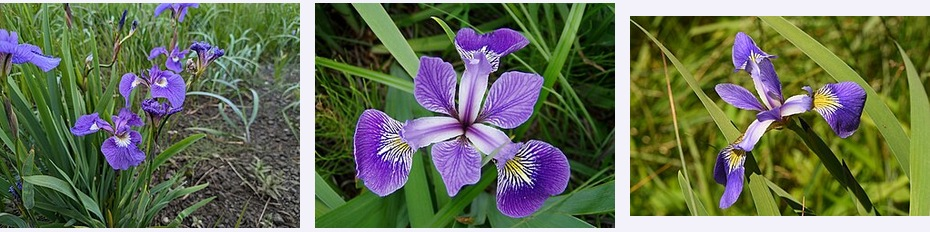

| 图中位置 | 中文名 | 英文常用名与学名 | 外观观察 |
|---|---|---|---|
| 左 | **山鸢尾** | Bristle-pointed iris · *Iris setosa* | 花常呈蓝紫色，外侧的萼片宽大，内侧的花瓣很小。 |
| 中 | **变色鸢尾** | Northern blue flag · *Iris versicolor* | 花常呈蓝紫色，可观察到外侧萼片上的浅色区域和深色脉纹。 |
| 右 | **维吉尼亚鸢尾** | Virginia iris · *Iris virginica* | 图中花呈紫色，可看到向外展开的萼片和比较直立的花瓣。 |

照片帮助你认识物种和花的结构。本次分类所用的输入是表格中的四项尺寸。

**照片来源**（从左到右，缩放排版）：[Philip Vanbergen](https://commons.wikimedia.org/wiki/File:Iris_setosa_at_Togiak,_United_States.jpg) · [CC0 1.0](https://creativecommons.org/publicdomain/zero/1.0/)；[Danielle Langlois](https://commons.wikimedia.org/wiki/File:Iris_versicolor_3.jpg) · [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/)；[Amaury Laporte](https://commons.wikimedia.org/wiki/File:Iris_Virginica_Purple_Flower_1.jpg) · [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/)。外观资料参见 [RHS 山鸢尾资料](https://www.rhs.org.uk/plants/9355/iris-setosa/details)、[北卡州立大学变色鸢尾资料](https://plants.ces.ncsu.edu/plants/iris-versicolor/)和 [USDA 维吉尼亚鸢尾资料](https://plants.sc.egov.usda.gov/DocumentLibrary/plantguide/pdf/pg_irvi.pdf)。

### 1.2 四项尺寸分别量什么

在鸢尾花上，外侧常向下展开的片状结构是这里说的**萼片**（sepal），内侧的片状结构是**花瓣**（petal）。下面把两种结构分别画成简化轮廓。每个结构记录一个长度（length）和一个宽度（width），单位都是厘米（cm）。示意图用于辨认尺寸方向。

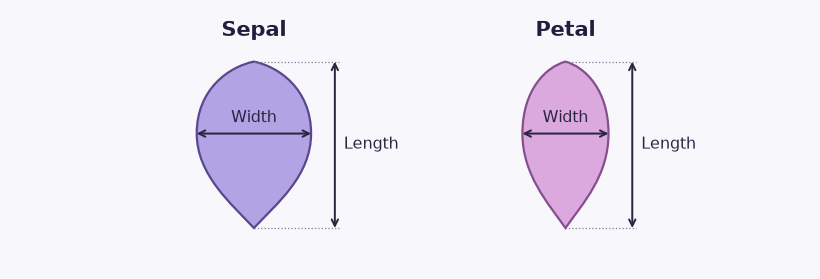

## 2. 读懂数据表

数据由 [scikit-learn 的 load_iris()](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html) 提供，共 **150 朵，三个物种各 50 朵**。表中每行是一朵花，四列尺寸是模型的**输入特征**，物种是模型要预测的**标签**。最后一列是物种的数字编号，便于程序存储和比较。

下表从每个物种各取两朵，展示原始数据的样子。

| 萼片长 / Sepal length（cm） | 萼片宽 / Sepal width（cm） | 花瓣长 / Petal length（cm） | 花瓣宽 / Petal width（cm） | 物种 | 标签编号 |
| ---: | ---: | ---: | ---: | --- | ---: |
| 5.1 | 3.5 | 1.4 | 0.2 | 山鸢尾 | 0 |
| 4.9 | 3.0 | 1.4 | 0.2 | 山鸢尾 | 0 |
| 7.0 | 3.2 | 4.7 | 1.4 | 变色鸢尾 | 1 |
| 6.4 | 3.2 | 4.5 | 1.5 | 变色鸢尾 | 1 |
| 6.3 | 3.3 | 6.0 | 2.5 | 维吉尼亚鸢尾 | 2 |
| 5.8 | 2.7 | 5.1 | 1.9 | 维吉尼亚鸢尾 | 2 |

| 标签编号 | 0 | 1 | 2 |
| --- | --- | --- | --- |
| 数据集中的英文标签 | setosa | versicolor | virginica |

### 2.1 划分训练集和测试集

程序从 150 条记录中选出 112 条作为训练集，其余 38 条作为测试集。固定随机种子，让大家使用相同的划分。

| 变量 | 保存的内容 | 在作业中的用途 |
|---|---|---|
| `X_train` | 112 朵训练花的四项尺寸 | 提供可供查找的邻居 |
| `y_train` | 112 朵训练花的物种编号 | 为每个邻居提供一个投票类别 |
| `X_test` | 38 朵测试花的四项尺寸 | 输入给模型做预测 |
| `y_test` | 38 朵测试花的真实物种编号 | 预测完成后用来核对结果 |

运行下面的准备单元。程序需要当前 Python 环境中的 scikit-learn 和 pandas，数据随 scikit-learn 提供。

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = load_iris()
X = iris.data
y = iris.target
species_names = np.array(["山鸢尾", "变色鸢尾", "维吉尼亚鸢尾"])
feature_columns = ["萼片长 (cm)", "萼片宽 (cm)", "花瓣长 (cm)", "花瓣宽 (cm)"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=15
)

print("训练样本数：", len(y_train))
print("测试样本数：", len(y_test))

训练样本数： 112
测试样本数： 38


In [5]:
y_train

array([0, 1, 2, 0, 0, 1, 2, 2, 0, 1, 0, 2, 2, 2, 2, 1, 1, 1, 0, 1, 2, 2,
       2, 2, 0, 2, 1, 2, 1, 0, 1, 0, 0, 2, 1, 1, 1, 1, 0, 2, 2, 2, 0, 1,
       0, 0, 2, 2, 1, 1, 2, 1, 0, 0, 1, 1, 1, 0, 2, 0, 1, 0, 1, 0, 2, 2,
       2, 0, 1, 0, 0, 1, 0, 2, 2, 2, 1, 0, 0, 2, 0, 1, 1, 2, 1, 1, 1, 0,
       0, 2, 1, 0, 2, 1, 0, 2, 1, 0, 0, 0, 0, 2, 0, 1, 0, 0, 2, 1, 2, 2,
       2, 2])

## 3. 任务一 · 创建模型并预测

补全下面标有 TODO 的三行。保留代码指定的变量名，后面的单元会继续使用它们。

1. **创建分类器。** 在 `KNeighborsClassifier` 的 `n_neighbors` 参数中填入邻居数 `5`。
2. **提供训练数据。** 把训练样本的特征和物种编号依次传给 `model.fit()`。
3. **进行预测。** 把测试样本的特征传给 `model.predict()`，将结果保存为 `y_pred`。

完成后运行代码。输出表中的测试样本编号是从 1 开始的顺序编号。你可以逐行比较真实物种与预测物种。

In [ ]:
# 请补充程序中缺失的内容
# TODO 1：设置邻居数
model = KNeighborsClassifier(n_neighbors=...)

# TODO 2：传入训练特征和训练标签
model.fit(..., ...)

# TODO 3：传入测试特征，得到预测标签
y_pred = model.predict(...)

results = pd.DataFrame({
    "测试样本编号": range(1, len(y_test) + 1),
    "真实物种": species_names[y_test],
    "预测物种": species_names[y_pred],
})
display(results)

## 4. 任务二 · 解释预测并计算准确率

### 4.1 解释第 33 朵测试花

运行下面的代码，先看这朵花的四项测量值、真实物种和预测物种，再看从训练集找到的 5 个邻居。距离越小，表示邻居在这四项尺寸上越接近待预测的花。每个邻居投一票。

根据表格填写下方的文字答案。请写出三种物种各获得几票、模型预测成了哪一种，并说明预测是否正确以及得出这个预测的依据。

In [7]:
sample_number = 33
sample_index = sample_number - 1

sample_table = pd.DataFrame(
    [X_test[sample_index]], columns=feature_columns
)
sample_table["真实物种"] = species_names[y_test[sample_index]]
sample_table["预测物种"] = species_names[y_pred[sample_index]]
display(sample_table)

distances, neighbor_indices = model.kneighbors(
    X_test[sample_index:sample_index + 1]
)
neighbor_table = pd.DataFrame({
    "邻居顺序": range(1, model.n_neighbors + 1),
    "距离": distances[0].round(3),
    "邻居物种": species_names[y_train[neighbor_indices[0]]],
})
display(neighbor_table)

,萼片长 (cm),萼片宽 (cm),花瓣长 (cm),花瓣宽 (cm),真实物种,预测物种
0,6.3,2.5,4.9,1.5,变色鸢尾,维吉尼亚鸢尾


,邻居顺序,距离,邻居物种
0,1,0.361,维吉尼亚鸢尾
1,2,0.361,维吉尼亚鸢尾
2,3,0.412,维吉尼亚鸢尾
3,4,0.424,变色鸢尾
4,5,0.436,维吉尼亚鸢尾


**我的解释**

- 山鸢尾：___ 票。变色鸢尾：___ 票。维吉尼亚鸢尾：___ 票。
- 模型预测为 ___，真实物种是 ___。
- 预测结果是否正确？模型为什么会作出这个判断？___

### 4.2 计算测试集上的准确率

准确率是预测正确的样本在全部测试样本中所占的比例。

$$
\text{准确率} = \frac{\text{预测正确数}}{\text{测试样本总数}}
$$

下方代码已逐个核对预测标签，得到正确数 `correct_count` 和测试样本总数 `total_count`。请用这两个变量补全 **TODO 4**，运行后将正确数、总数和百分比填入代码下方的文字答案。

In [ ]:
correct_count = (y_pred == y_test).sum()
total_count = len(y_test)

# TODO 4：计算准确率
accuracy = ...

print("预测正确数：", correct_count)
print("测试样本总数：", total_count)
print(f"测试集准确率：{accuracy:.2%}")

**我的结果**

在 ___ 朵测试花中，模型正确预测了 ___ 朵，准确率为 ___%。

## 5. 扩展阅读 · 原来的手写 KNN 程序（选读）

下面是原 Notebook 的 KNN 实现。`dis` 计算欧氏距离，`knn_classfy` 为一朵花寻找邻居并投票，`predict` 把同样的规则用于多朵花。运行这个单元可以查看手写版本在同一测试集上的准确率。

In [ ]:
from collections import Counter

class Knn():
    def __init__(self,k=5):
        self.k = k

    def fit(self,x,y):
        self.x = x
        self.y = y

    def dis(self,instant1, instant2):  # 求欧式距离
        dist = np.sqrt(np.sum((instant1 - instant2) ** 2))
        return dist

    def knn_classfy(self,X,y,test):
        # 1. 计算待预测样本到每个训练样本的距离。
        distances = [self.dis(x,test) for x in X]
        # 2. 按距离排序，取最近的 K 个训练样本。
        kneighbors = np.argsort(distances)[:self.k] #选取前K个邻居
        # 3. 统计邻居类别票数，返回票数最多的类别。
        count = Counter(y[kneighbors]) #记标签的个数
        return count.most_common()[0][0]  #统计出现次数最多的标签

    def predict(self,test_x):
        pre = [self.knn_classfy(self.x,self.y,i) for i in test_x]  # 预测的标签集
        return  pre

    def score(self,test_x,test_y):
        pre = [self.knn_classfy(self.x,self.y,i) for i in test_x]  # 预测的标签集
        col = np.count_nonzero((pre == test_y))  # 统计测试集的标签和预测的标签相同的个数
        return col / test_y.size

# 沿用上面准备的数据，对比原手写程序的结果。
manual_model = Knn(5)
manual_model.fit(X_train, y_train)
manual_predictions = manual_model.predict(X_test)
print(f"手写 KNN 的测试集准确率：{manual_model.score(X_test, y_test):.2%}")

## 6. 开放题 · 如果只能量两项尺寸

假设现场测量时间有限，每朵花只能测四项特征中的两项。你会保留哪两项？请说明理由，并用自己的话写出你会怎样利用现有数据检验这个选择。

用 2–4 句话回答即可。

**我的回答**

（在这里填写你的回答。）